In [3]:
import pandas as pd
import numpy as np

In [4]:
df = pd.read_csv('DurData_custpurchase.csv')

## Understand the basic structure of the data

In [5]:
df.columns

Index(['Unnamed: 0', 'Household_ID', 'N_catg1', 'N_catg2', 'N_catg3',
       'N_catg4', 'N_catg5', 'N_catg6', 'N_catg7', 'N_catg8', 'N_catg9',
       'N_catg10', 'N_catg11', 'N_catg12', 'N_catg13', 'N_catg14', 'N_catg15',
       'E_catg1', 'E_catg2', 'E_catg3', 'E_catg4', 'E_catg5', 'E_catg6',
       'E_catg7', 'E_catg8', 'E_catg9', 'E_catg10', 'E_catg11', 'E_catg12',
       'E_catg13', 'E_catg14', 'E_catg15', 'Household_Income',
       'Age_Household_Head', 'Number_Of_Kids', 'Total_Number_Of_Transactions',
       'Number_Of_Online_Purchase', 'Number_Of_Stores_Visited',
       'Number_Of_Returns', 'Number_Of_Different_Categories'],
      dtype='object')

In [22]:
basisvars = df[[col for col in df.columns if col.startswith('N_' )]]

In [23]:
basisvars.head()

,N_catg1,N_catg2,N_catg3,N_catg4,N_catg5,N_catg6,N_catg7,N_catg8,N_catg9,N_catg10,N_catg11,N_catg12,N_catg13,N_catg14,N_catg15
0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0
1,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0
2,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0
3,0,0,0,0,1,0,0,2,0,0,6,1,0,0,0
4,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0


In [24]:
# given the sd = 0 for the third column, we need to drop it
basisvars = basisvars.drop(basisvars.columns[basisvars.std()==0], axis=1)
basisvars.head()

,N_catg1,N_catg2,N_catg3,N_catg4,N_catg5,N_catg6,N_catg7,N_catg8,N_catg9,N_catg10,N_catg11,N_catg12,N_catg13,N_catg14,N_catg15
0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0
1,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0
2,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0
3,0,0,0,0,1,0,0,2,0,0,6,1,0,0,0
4,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0


In [25]:
# Normalize basisvars: (value - mean) / std
basisvars_norm = (basisvars - basisvars.mean()) / basisvars.std()
basisvars_norm.head()

,N_catg1,N_catg2,N_catg3,N_catg4,N_catg5,N_catg6,N_catg7,N_catg8,N_catg9,N_catg10,N_catg11,N_catg12,N_catg13,N_catg14,N_catg15
0,-0.503992,-0.215677,-0.071001,-0.127324,-0.406308,-0.169845,-0.277133,-0.349537,-0.349792,-0.50961,-0.506063,-0.453697,-0.554179,0.517772,-0.30849
1,-0.503992,-0.215677,-0.071001,-0.127324,-0.406308,-0.169845,-0.277133,-0.349537,-0.349792,-0.50961,-0.051978,-0.453697,0.226165,-0.528478,-0.30849
2,-0.503992,-0.215677,-0.071001,-0.127324,-0.406308,-0.169845,-0.277133,-0.349537,-0.349792,-0.50961,-0.051978,-0.453697,-0.554179,-0.528478,-0.30849
3,-0.503992,-0.215677,-0.071001,-0.127324,0.337166,-0.169845,-0.277133,0.608512,-0.349792,-0.50961,2.218452,0.208739,-0.554179,-0.528478,-0.30849
4,0.065115,-0.215677,-0.071001,-0.127324,-0.406308,-0.169845,-0.277133,-0.349537,-0.349792,-0.50961,-0.506063,-0.453697,-0.554179,0.517772,-0.30849


## Performing K-means clustering analysis

In [26]:
from sklearn.cluster import KMeans

# Perform k-means clustering with 3 clusters (you can adjust n_clusters as needed)
kmeans = KMeans(n_clusters=3, random_state=42)
clusters = kmeans.fit_predict(basisvars_norm)

# Add cluster labels to the normalized dataframe
basisvars_norm['cluster'] = clusters

basisvars_norm.head()

,N_catg1,N_catg2,N_catg3,N_catg4,N_catg5,N_catg6,N_catg7,N_catg8,N_catg9,N_catg10,N_catg11,N_catg12,N_catg13,N_catg14,N_catg15,cluster
0,-0.503992,-0.215677,-0.071001,-0.127324,-0.406308,-0.169845,-0.277133,-0.349537,-0.349792,-0.50961,-0.506063,-0.453697,-0.554179,0.517772,-0.30849,0
1,-0.503992,-0.215677,-0.071001,-0.127324,-0.406308,-0.169845,-0.277133,-0.349537,-0.349792,-0.50961,-0.051978,-0.453697,0.226165,-0.528478,-0.30849,0
2,-0.503992,-0.215677,-0.071001,-0.127324,-0.406308,-0.169845,-0.277133,-0.349537,-0.349792,-0.50961,-0.051978,-0.453697,-0.554179,-0.528478,-0.30849,0
3,-0.503992,-0.215677,-0.071001,-0.127324,0.337166,-0.169845,-0.277133,0.608512,-0.349792,-0.50961,2.218452,0.208739,-0.554179,-0.528478,-0.30849,0
4,0.065115,-0.215677,-0.071001,-0.127324,-0.406308,-0.169845,-0.277133,-0.349537,-0.349792,-0.50961,-0.506063,-0.453697,-0.554179,0.517772,-0.30849,0


In [27]:
# Calculate the size of each cluster
cluster_sizes = basisvars_norm['cluster'].value_counts().sort_index()

# Calculate the average of the variables for each cluster
cluster_means = basisvars_norm.groupby('cluster').mean()

# Combine the size and means into a single DataFrame
summary = cluster_means.copy()
summary['size'] = cluster_sizes

summary

,N_catg1,N_catg2,N_catg3,N_catg4,N_catg5,N_catg6,N_catg7,N_catg8,N_catg9,N_catg10,N_catg11,N_catg12,N_catg13,N_catg14,N_catg15,size
cluster,,,,,,,,,,,,,,,,
0,-0.162272,-0.083748,-0.071001,-0.071995,-0.153479,-0.092133,-0.142594,-0.081722,-0.137503,-0.156150,-0.162821,-0.120802,-0.158665,-0.155170,-0.097438,17382
1,0.861865,0.173792,14.083680,0.266826,1.110379,0.617602,0.345102,0.215712,0.969964,0.885079,1.696253,1.818459,0.788013,0.758410,0.652858,100
2,1.114276,0.586116,-0.071001,0.499076,1.041861,0.627426,0.995948,0.570057,0.934426,1.069964,1.084162,0.781555,1.091730,1.068183,0.663565,2454


## Plot the SSE and find the k-value

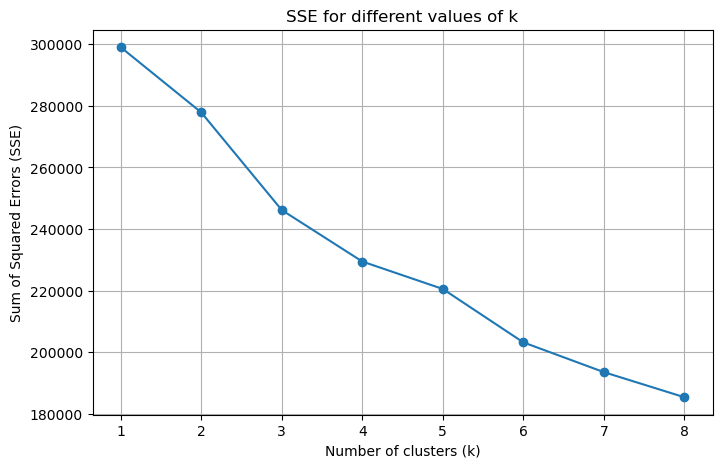

In [29]:
import matplotlib.pyplot as plt

# List of k values to test
max_segments = 8
k_values = range(1, max_segments + 1)
sse = []

# Calculate SSE for each k
for k in k_values:
    kmeans_tmp = KMeans(n_clusters=k, random_state=42)
    kmeans_tmp.fit(basisvars_norm.drop('cluster', axis=1))
    sse.append(kmeans_tmp.inertia_)

# Plot SSE vs k
plt.figure(figsize=(8, 5))
plt.plot(k_values, sse, marker='o')
plt.xlabel('Number of clusters (k)')
plt.ylabel('Sum of Squared Errors (SSE)')
plt.title('SSE for different values of k')
plt.xticks(k_values)
plt.grid(True)
plt.show()

If choosing among 3, 4 or 5 segments, the best option is 3 segments